# 02 - The masked-patch dataset (proof of concept for diffusion inpainting)

**Goal:** show what the inpainting dataset built by `scripts/make_masked_pairs.py` contains, and walk through individual cutting paths to see which windows were kept, which were rejected, and where the masks fall.

**Task being set up:** a model sees a spectrogram patch with some time frames missing (dropouts of 10-100 ms) and must reconstruct them. Ground truth is the original patch.

| Choice | Value | Why |
|---|---|---|
| Sensor | 2 (base ISS) | by far the least clipped, so clean ground truth exists |
| Windows | 17152 samples (~0.357 s), non-overlapping, inside cutting paths only | fixed size for the model; idle time is excluded |
| Representation | log-magnitude STFT, 128 bins (0-6 kHz) x 64 frames | sensor 2 has no energy above ~6 kHz |
| Keep rule | no full-scale samples | clean ground truth. No loudness gate: quieter stretches inside a path are still cutting |
| Data | IMI only (KRPM left out) | keeps the story simple |
| Split | by session | sessions differ in tool, material and gain |

Regenerate the data with `python scripts/make_masked_pairs.py`.

## 1. Setup and load

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import signal

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
try:
    import mtcut
except ImportError:  # package not installed (`pip install -e .`): use the source tree
    sys.path.insert(0, str(ROOT / "src"))
    import mtcut

from mtcut import get_session, segment_table
from mtcut.labels import consensus
from mtcut.config import PROCESSED_DIR, SAMPLE_RATE
from mtcut.features import frame_rms, rms_db
from mtcut.masking import (BIN_HZ, DB_HI, DB_LO, FRAME_S, HOP, N_BINS, N_FFT, N_FRAMES, PATCH_SAMPLES,
                           apply_mask, idle_level_db)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
SENSOR = 2
SPLIT_COLOR = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}
PATCH_S = PATCH_SAMPLES / SAMPLE_RATE
KHZ_MAX = N_BINS * BIN_HZ / 1000

npz = np.load(PROCESSED_DIR / "masked" / "patches.npz")
clean, mask = npz["clean"].astype(np.float32), npz["mask"]
meta = pd.read_csv(PROCESSED_DIR / "masked" / "patches.csv", index_col="patch_idx")
meta["above_idle_db"] = meta.rms_db - meta.idle_db

# path-level labels for every path (also those with no kept patch)
seg = segment_table()
seg["chatter_max"] = consensus(seg["chatter_op1"], seg["chatter_op2"], "max")
PATH_LABEL = seg.set_index(["session", "path_idx"]).chatter_max
print(f"clean {clean.shape} (patches, freq bins, time frames), mask {mask.shape}")
print(f"patch = {PATCH_S*1000:.0f} ms, {N_FRAMES} frames of {FRAME_S*1000:.2f} ms, {N_BINS} bins of {BIN_HZ:.1f} Hz (0-{KHZ_MAX:.1f} kHz)")

clean (1461, 128, 64) (patches, freq bins, time frames), mask (1461, 64)
patch = 357 ms, 64 frames of 5.33 ms, 128 bins of 46.9 Hz (0-6.0 kHz)


## 2. What is in it

Patch counts per split and session. `chatter_frac` is the share of patches whose cutting path was scored chatter (2) by the stricter-of-two-operators rule (`max`). The labels are not used by the inpainting task, but the class mix matters when interpreting results.

patches  paths  chatter_frac  above_idle_db
split session                                              
test  Exp0-1        103     20          0.00           9.33
      Exp1-1-A       36     13          0.00          15.18
      Exp1-8          5      2          0.00          15.51
train Exp0-2         50     10          0.00          19.78
      Exp1-1-B       28     11          0.00          15.91
      Exp1-2          8      3          0.00          16.10
      Exp1-3          1      1          0.00          14.72
      Exp1-4         28     12          0.00          14.15
      Exp1-5          9      3          0.00          14.31
      Exp1-7         28     13          0.00          14.04
      Exp1-9          3      1          0.00          13.97
      Exp3-2        474     31          0.66           6.94
      Exp4-3        272     38          1.00           4.05
      Exp4-3-2      329     49          0.87           3.82
val   Exp0-3         48     16          0.00          23.43
      Exp1-1-2       36     15          0.03          14.00
      Exp1-6          3      1          0.00          16.19

,patches,sessions
split,,
test,144,3
train,1230,11
val,87,3


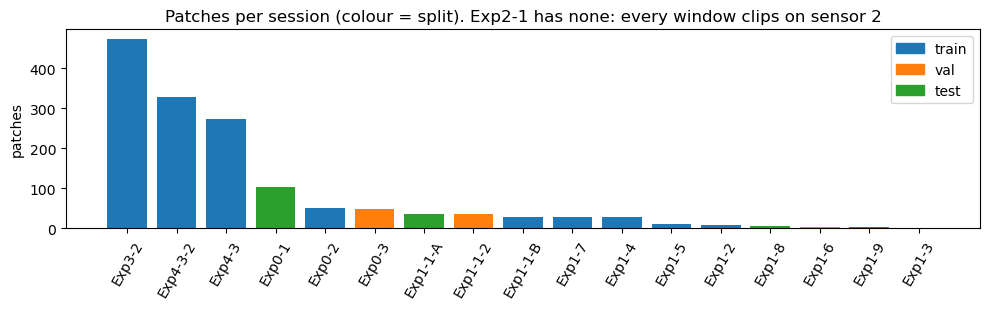

In [2]:
summary = (meta.groupby(["split", "session"])
           .agg(patches=("path_idx", "size"), paths=("path_idx", "nunique"),
                chatter_frac=("chatter_max", lambda s: (s == 2).mean() if s.notna().any() else np.nan),
                above_idle_db=("above_idle_db", "mean"))
           .round(2))
display(summary)
display(meta.groupby("split").agg(patches=("path_idx", "size"), sessions=("session", "nunique")))

order = meta.groupby("session").size().sort_values(ascending=False)
split_of = meta.groupby("session").split.first()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(order.index, order.values, color=[SPLIT_COLOR[split_of[s]] for s in order.index])
ax.set_ylabel("patches"); ax.tick_params(axis="x", rotation=60)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SPLIT_COLOR.values()], labels=list(SPLIT_COLOR))
ax.set_title("Patches per session (colour = split). Exp2-1 has none: every window clips on sensor 2")
plt.tight_layout(); plt.show()

## 3. Why only cutting windows: one session on a timeline

Sensor-2 level (50 ms RMS) over a whole session. Shaded = `cutting.csv` intervals.  Green ticks mark kept patches. Note how much of the recording is not cutting. Some stretches inside the shaded intervals are quieter than others; they are kept. Only clipped windows are dropped.

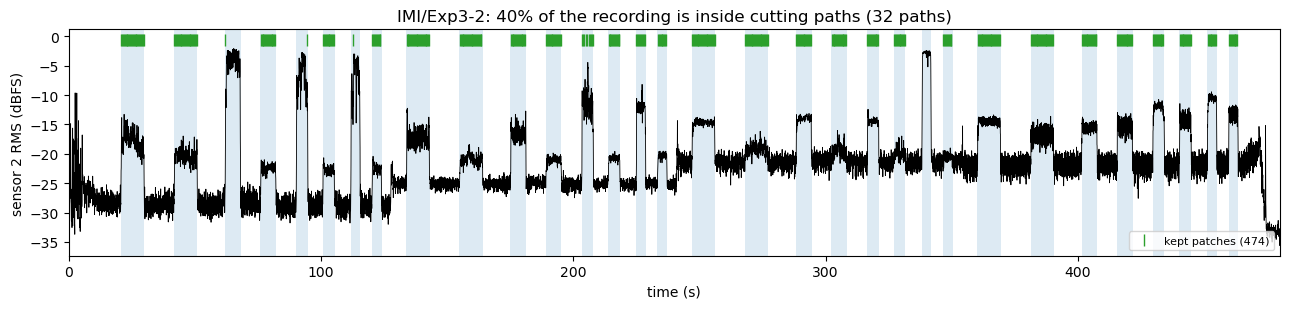

In [3]:
def timeline(session_name):
    s = get_session(session_name)
    x = s.load(SENSOR, as_float=False)
    iv = s.intervals()
    t, r = frame_rms(np.asarray(x, dtype=np.float32) / 32768.0)
    db = 20 * np.log10(r + 1e-9)
    fig, ax = plt.subplots(figsize=(13, 3.2))
    ax.plot(t, db, lw=0.6, color="k")
    for _, row in iv.iterrows():
        ax.axvspan(row.start, row.end, color="tab:blue", alpha=0.15, lw=0)
    kept = meta[meta.session == session_name]
    ax.plot(kept.start_s + PATCH_S / 2, np.full(len(kept), db.max() + 1.5), "|", color="tab:green", ms=8,
            label=f"kept patches ({len(kept)})")
    ax.set_xlim(0, s.duration); ax.set_xlabel("time (s)"); ax.set_ylabel("sensor 2 RMS (dBFS)")
    ax.set_title(f"{s.id}: {iv.duration.sum() / s.duration:.0%} of the recording is inside cutting paths ({len(iv)} paths)")
    ax.legend(loc="lower right", fontsize=8, ncol=2); plt.tight_layout(); plt.show()

timeline("Exp3-2")

## 4. Patch gallery: clean target vs masked input

Top row: the clean target. Bottom row: what the model is given (masked frames shown at the lowest value, i.e. dark). Horizontal stripes are the tooth-passing harmonics from forced vibration; chatter adds energy at other frequencies. Three random normal and three random chatter patches.

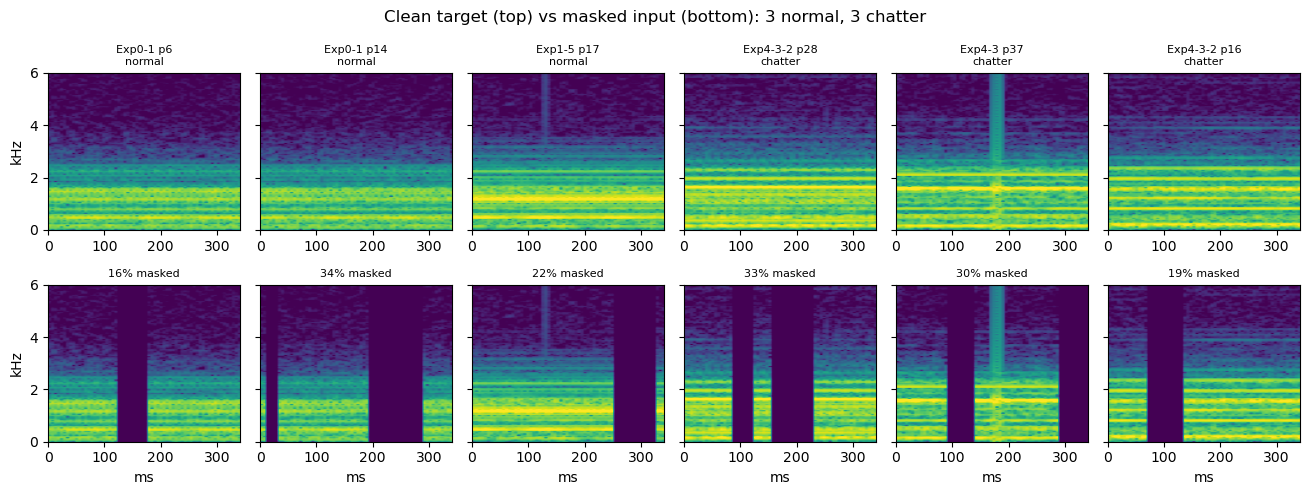

In [4]:
LABEL_NAME = {0.0: "normal", 1.0: "uncertain", 2.0: "chatter"}


def show_patch(ax, spec, title=None, masked=None):
    img = np.array(spec)
    if masked is not None:
        img = apply_mask(img, masked, fill=DB_LO)
    ax.imshow(img, origin="lower", aspect="auto", vmin=-100, vmax=-20,
              extent=[0, N_FRAMES * FRAME_S * 1000, 0, KHZ_MAX])
    if title:
        ax.set_title(title, fontsize=8)


rng = np.random.default_rng(3)
picks = []
for sel in [meta.chatter_max == 0, meta.chatter_max == 2]:
    picks += list(rng.choice(meta.index[sel], 3, replace=False))
fig, ax = plt.subplots(2, len(picks), figsize=(2.2 * len(picks), 5), sharey=True)
for j, i in enumerate(picks):
    r = meta.loc[i]
    lab = LABEL_NAME[r.chatter_max]
    show_patch(ax[0, j], clean[i], f"{r.session} p{r.path_idx}\n{lab}")
    show_patch(ax[1, j], clean[i], f"{mask[i].mean():.0%} masked", masked=mask[i])
    ax[1, j].set_xlabel("ms")
ax[0, 0].set_ylabel("kHz"); ax[1, 0].set_ylabel("kHz")
fig.suptitle("Clean target (top) vs masked input (bottom): 3 normal, 3 chatter")
plt.tight_layout(); plt.show()

## 5. Walking through single cutting paths

For one path this shows, on the full-resolution spectrogram of the raw recording (with 0.3 s of padding around the path):

* **Top:** every candidate window the script considered. Green = kept, red = rejected because it contains clipped samples. The dashed lines are the `cutting.csv` start and end.
* **Bottom:** the model input for the same path: only the kept windows, with the masked frames blanked (white). Everything outside the kept windows is not part of the dataset.

In [5]:
STATUS_COLOR = {"kept": "tab:green", "clipped": "tab:red"}


def path_windows(x, i0, i1):
    out = []
    for start in range(i0, i1 - PATCH_SAMPLES + 1, PATCH_SAMPLES):
        w = np.asarray(x[start:start + PATCH_SAMPLES])
        clip = float(np.mean(np.abs(w.astype(np.int32)) >= 32767))
        level = rms_db(w.astype(np.float32) / 32768.0)
        status = "clipped" if clip > 0 else "kept"
        out.append({"start": start, "t": start / SAMPLE_RATE, "clip": clip, "level": level, "status": status})
    return pd.DataFrame(out)


def path_view(session_name, path_idx, pad=0.3):
    s = get_session(session_name)
    x = s.load(SENSOR, as_float=False)
    iv = s.intervals().loc[path_idx]
    i0, i1 = int(round(iv.start * SAMPLE_RATE)), min(len(x), int(round(iv.end * SAMPLE_RATE)))
    win = path_windows(x, i0, i1)

    a, b = max(0, i0 - int(pad * SAMPLE_RATE)), min(len(x), i1 + int(pad * SAMPLE_RATE))
    xf = np.asarray(x[a:b], dtype=np.float32) / 32768.0
    _, tt, Z = signal.stft(xf, fs=SAMPLE_RATE, nperseg=N_FFT, noverlap=N_FFT - HOP, boundary=None, padded=False)
    db = np.clip(20 * np.log10(np.abs(Z[:N_BINS]) + 1e-6), DB_LO, DB_HI)
    t0, t1 = a / SAMPLE_RATE, b / SAMPLE_RATE
    ext = [t0 + tt[0], t0 + tt[-1], 0, KHZ_MAX]

    sel = meta[(meta.session == session_name) & (meta.path_idx == path_idx)]
    raw_lab = PATH_LABEL.get((session_name, path_idx), np.nan)
    lab = "no label" if pd.isna(raw_lab) else LABEL_NAME[raw_lab]
    counts = win.status.value_counts().to_dict()

    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)
    ax[0].imshow(db, origin="lower", aspect="auto", vmin=-100, vmax=-20, extent=ext)
    for _, w in win.iterrows():
        ax[0].add_patch(plt.Rectangle((w.t, 0.05), PATCH_S, KHZ_MAX - 0.1, fill=False, lw=2, ec=STATUS_COLOR[w.status]))
    for xv in (iv.start, iv.end):
        ax[0].axvline(xv, color="w", ls="--", lw=1)
    ax[0].set_ylabel("kHz")
    ax[0].set_title(f"{s.id} path {path_idx} ({lab}, {iv.end - iv.start:.2f} s): candidate windows {counts}. "
                    "Dashed = cutting.csv start/end", fontsize=10)

    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("white")
    for i, r in sel.iterrows():
        img = apply_mask(clean[i], mask[i], fill=np.nan)
        ax[1].imshow(np.ma.masked_invalid(img), origin="lower", aspect="auto", vmin=-100, vmax=-20, cmap=cmap,
                     extent=[r.start_s, r.start_s + PATCH_S, 0, KHZ_MAX])
    ax[1].set_xlim(t0, t1); ax[1].set_ylim(0, KHZ_MAX)
    ax[1].set_facecolor("0.85"); ax[1].set_ylabel("kHz"); ax[1].set_xlabel("time in recording (s)")
    ax[1].set_title(f"Model input: {len(sel)} kept windows, masked frames white, grey = not in the dataset", fontsize=10)
    plt.tight_layout(); plt.show()
    assert len(sel) == counts.get("kept", 0), "notebook and script disagree on kept windows"
    return win


# pick readable examples: the shortest path with at least 4 kept windows in each category
n_per_path = meta.groupby(["session", "path_idx"]).size().reset_index(name="n")
lab_of = meta.groupby(["session", "path_idx"]).chatter_max.first().reset_index()
good = n_per_path[n_per_path.n >= 4].merge(lab_of, on=["session", "path_idx"]).sort_values("n")
ex_normal = good[good.chatter_max == 0].iloc[0]
ex_chatter = good[good.chatter_max == 2].iloc[0]
print(ex_normal.session, ex_normal.path_idx, "|", ex_chatter.session, ex_chatter.path_idx)

Exp1-1-2 9 | Exp4-3 18


### 5a. A normal (non-chatter) cutting path

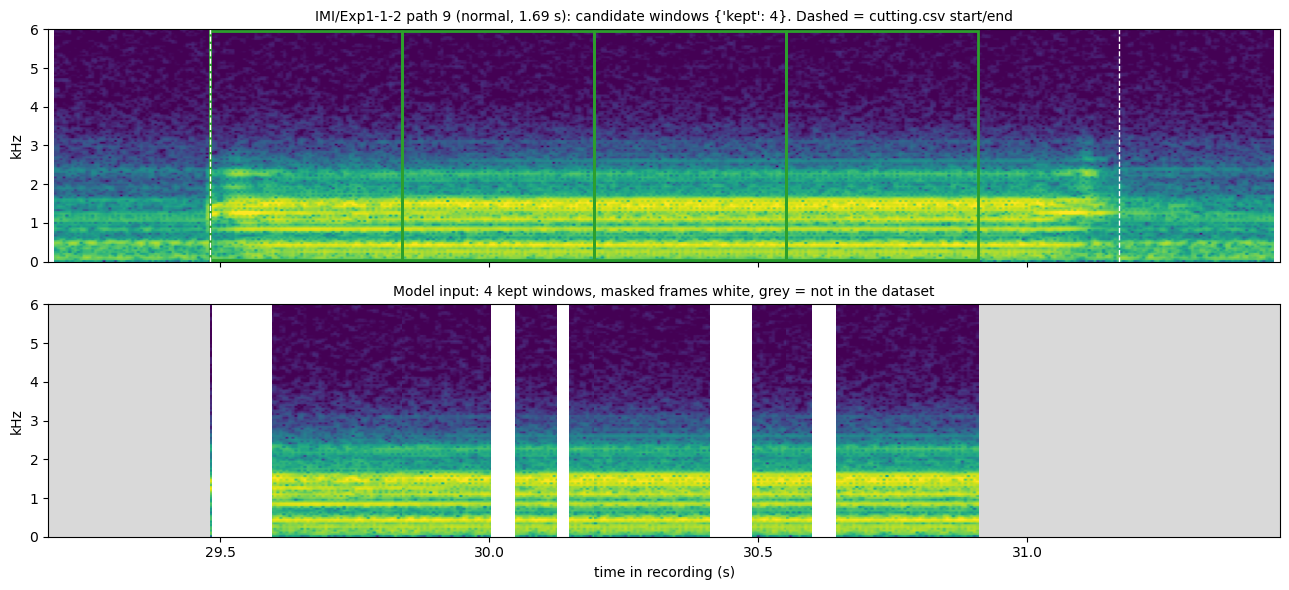

In [6]:
_ = path_view(ex_normal.session, int(ex_normal.path_idx))

### 5b. A chatter cutting path

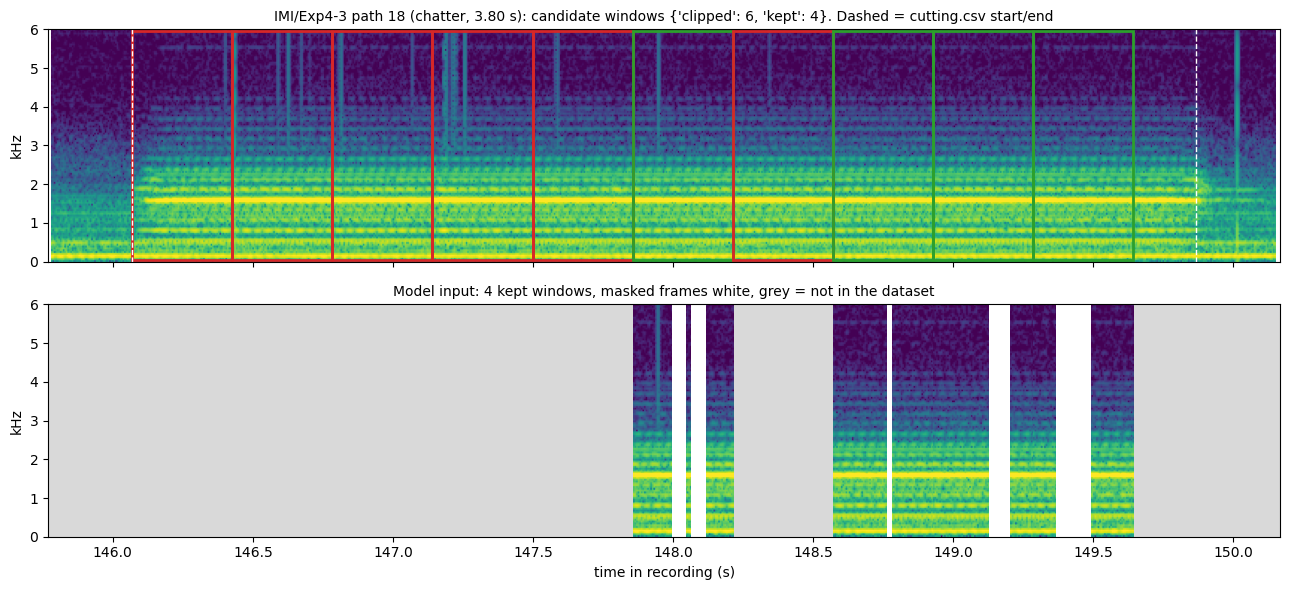

In [7]:
_ = path_view(ex_chatter.session, int(ex_chatter.path_idx))

### 5c. A path that loses windows

The table counts what the clipping filter removes in four sessions, then the path with the most rejected windows is shown. Loud chatter cuts are the ones that clip on sensor 2, so the clean-only rule biases the dataset toward gentler cuts. This matters when reading the results.

,windows,kept,clipped,kept_frac
session,,,,
Exp1-1-2,81,36,45,0.44
Exp1-4,77,28,49,0.36
Exp3-2,524,474,50,0.90
Exp4-3-2,396,329,67,0.83


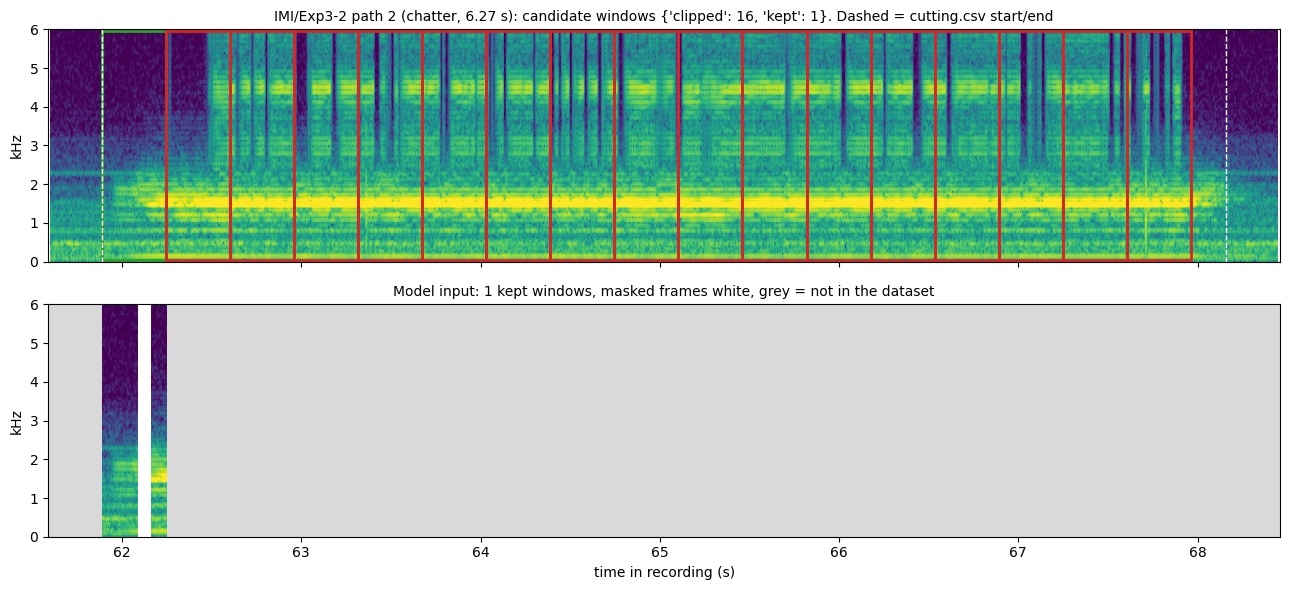

In [8]:
rows = []
for sname in ["Exp1-1-2", "Exp3-2", "Exp4-3-2", "Exp1-4"]:
    s = get_session(sname)
    x = s.load(SENSOR, as_float=False)
    for pidx, iv in s.intervals().iterrows():
        w = path_windows(x, int(round(iv.start * SAMPLE_RATE)), min(len(x), int(round(iv.end * SAMPLE_RATE))))
        if len(w):
            rows.append({"session": sname, "path_idx": pidx, "windows": len(w), "kept": int((w.status == "kept").sum()),
                         "clipped": int((w.status == "clipped").sum())})
rej = pd.DataFrame(rows)
rej["rejected"] = rej.windows - rej.kept
tot = rej.groupby("session")[["windows", "kept", "clipped"]].sum()
tot["kept_frac"] = (tot.kept / tot.windows).round(2)
display(tot)
worst = rej[rej.windows >= 6].sort_values("rejected", ascending=False).iloc[0]
_ = path_view(worst.session, int(worst.path_idx))

## 6. The masks

Masks are fixed per patch (seeded) so every method is scored on the same dropouts. Each is 1 or 2 spans of 10-100 ms, covering all frequencies at once, as a sensor dropout would.

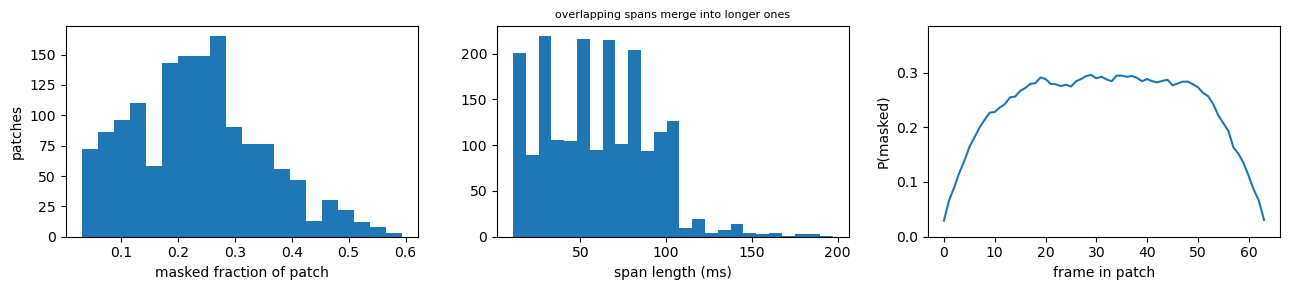

masked fraction: mean 0.23, max 0.59; spans: median 59 ms


In [9]:
spans = []
for m in mask:
    d = np.diff(np.concatenate([[0], m.astype(int), [0]]))
    spans += list((np.where(d == -1)[0] - np.where(d == 1)[0]) * FRAME_S * 1000)
pos = mask.mean(axis=0)

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].hist(mask.mean(axis=1), bins=20, color="tab:blue"); ax[0].set_xlabel("masked fraction of patch"); ax[0].set_ylabel("patches")
ax[1].hist(spans, bins=25, color="tab:blue"); ax[1].set_xlabel("span length (ms)")
ax[1].set_title("overlapping spans merge into longer ones", fontsize=8)
ax[2].plot(np.arange(N_FRAMES), pos); ax[2].set_ylim(0, pos.max() * 1.3); ax[2].set_xlabel("frame in patch"); ax[2].set_ylabel("P(masked)")
plt.tight_layout(); plt.show()
print(f"masked fraction: mean {mask.mean():.2f}, max {mask.mean(axis=1).max():.2f}; spans: median {np.median(spans):.0f} ms")

## 7. Normal vs chatter: average spectrum

Mean level per frequency bin, and how far above the session idle level the patches sit.

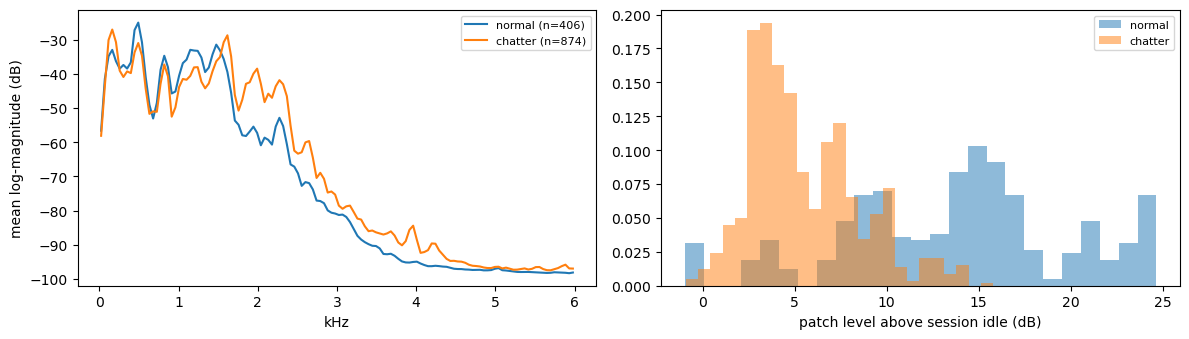

In [10]:
groups = {"normal": meta.chatter_max == 0, "chatter": meta.chatter_max == 2}
f_khz = (np.arange(N_BINS) + 0.5) * BIN_HZ / 1000
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, sel in groups.items():
    ax[0].plot(f_khz, clean[sel.values].mean(axis=(0, 2)), label=f"{name} (n={sel.sum()})")
    ax[1].hist(meta.loc[sel, "above_idle_db"], bins=25, alpha=0.5, label=name, density=True)
ax[0].set_xlabel("kHz"); ax[0].set_ylabel("mean log-magnitude (dB)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("patch level above session idle (dB)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Takeaways for the diffusion experiment

* The dataset is **cutting windows only**, one sensor, fixed-size log spectrograms with seeded dropout masks. Splits are by session.
* **Selection bias:** keeping only unclipped windows removes the loudest chatter cuts, and there is no loudness gate, so quiet stretches inside a path are included. Report results as "on unclipped cutting-path windows".
* **Imbalance:** a few sessions (Exp3-2, Exp4-3, Exp4-3-2) dominate the training set; the test sessions are mostly normal cuts.
* **Next:** interpolation baselines and metrics (notebook 03), then the RePaint-style diffusion model.